# EcoFOCIpy ADCP QC - 25CKP-14A

- mostly remove >500 cm/s flows in u/v


In [2]:
import xarray as xa
import numpy as np

import matplotlib.pyplot as plt

from EcoFOCIpy.plots import TimeSeriesStickPlot

/Users/bell/src/ecofocipy/src/EcoFOCIpy/__init__.py:62: UserWarning: Could not import all EcoFOCIpy submodules: cannot import name 'instruments' from partially initialized module 'EcoFOCIpy' (most likely due to a circular import) (/Users/bell/src/ecofocipy/src/EcoFOCIpy/__init__.py)
  warnings.warn(f"Could not import all EcoFOCIpy submodules: {e}")


In [5]:
xdf = xa.load_dataset('25bsp14a_0026m.trimmed.nc')

In [6]:
len(xdf.depth)

9

/Users/bell/src/ecofocipy/src/EcoFOCIpy/plots/TimeSeriesStickPlot.py:122: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(ax2.get_xticklabels(), visible=True)
/Users/bell/src/ecofocipy/src/EcoFOCIpy/plots/TimeSeriesStickPlot.py:122: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(ax2.get_xticklabels(), visible=True)
/Users/bell/src/ecofocipy/src/EcoFOCIpy/plots/TimeSeriesStickPlot.py:122: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(ax2.get_xticklabels(), visible=True)
/Users/bell/src/ecofocipy/src/EcoFOCIpy/plots/TimeSeriesStickPlot.py:122: UserWarning: set_ticklabels() shoul

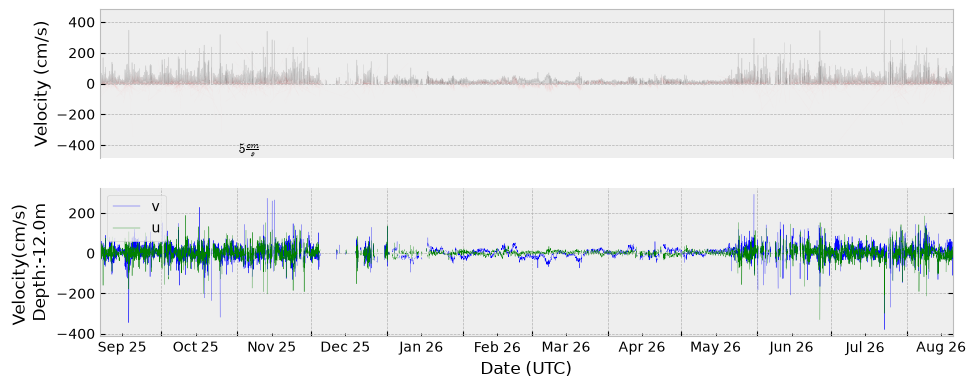

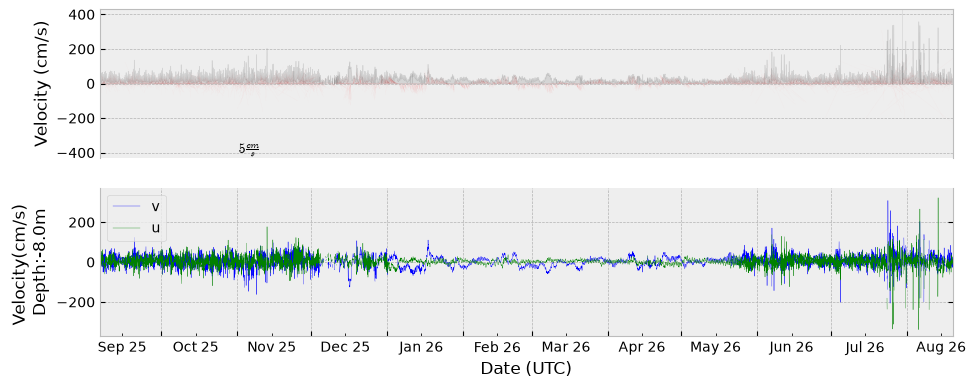

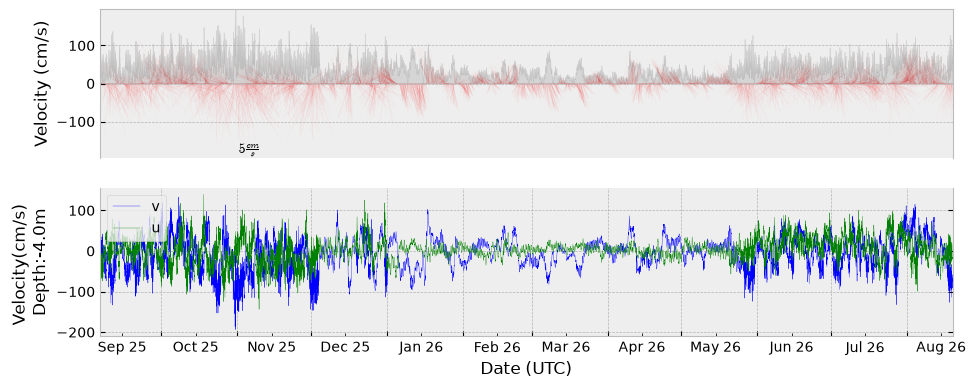

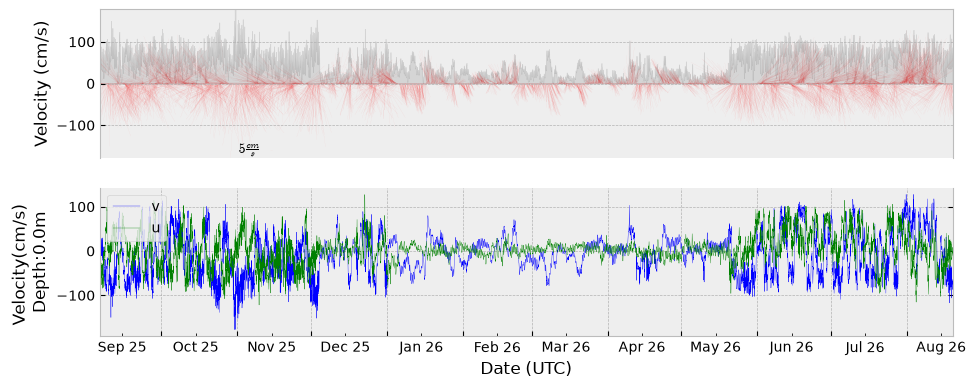

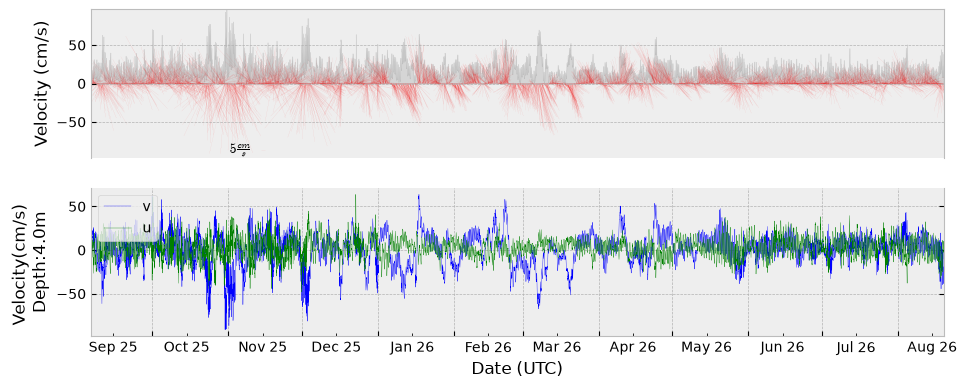

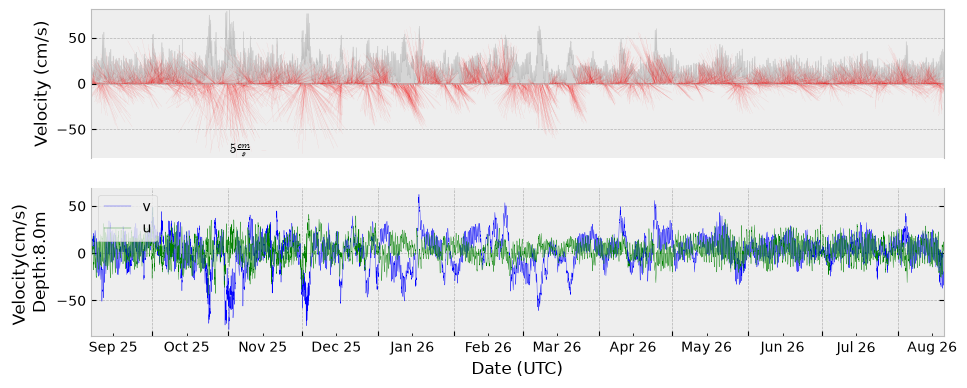

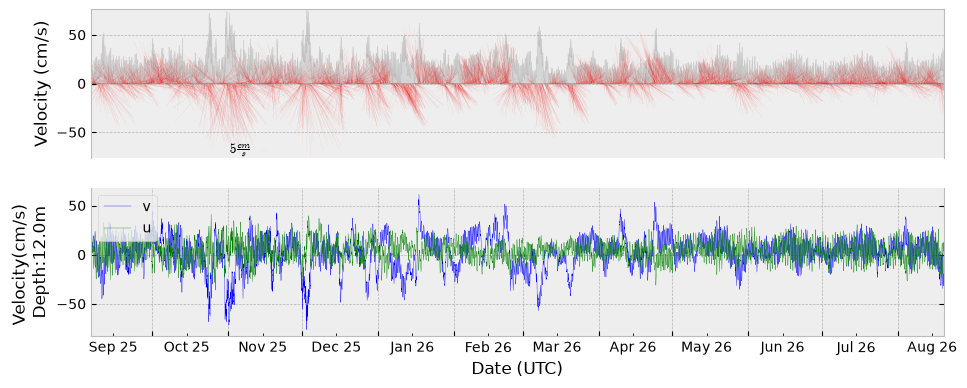

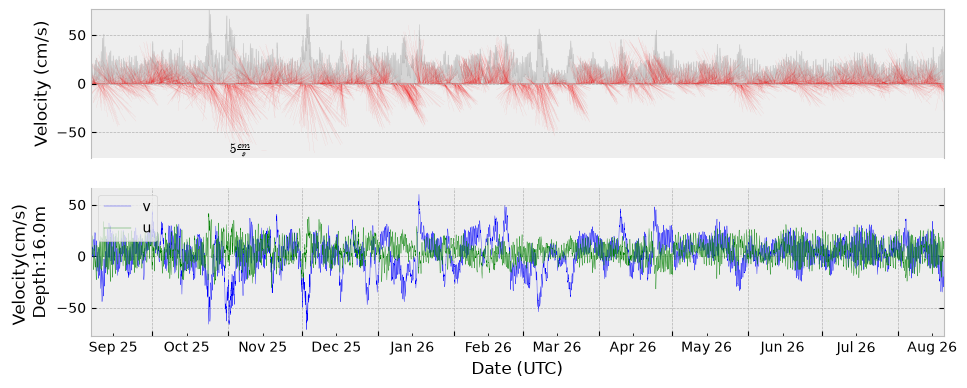

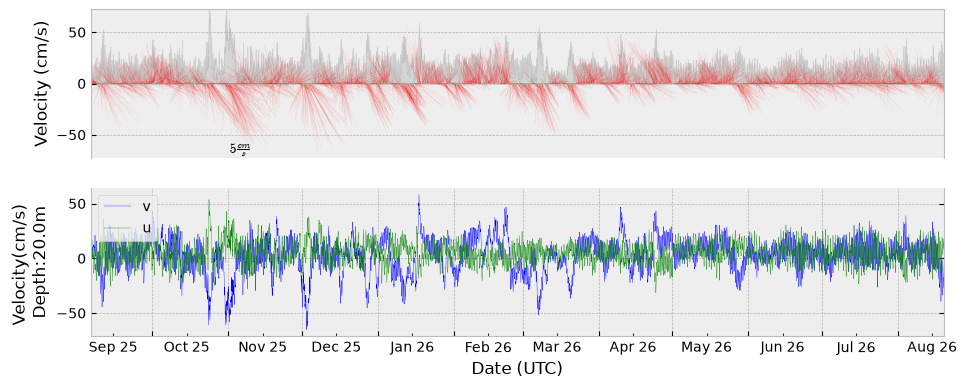

In [9]:
for i in range(0,len(xdf.depth),1):
    try:
        p1 = TimeSeriesStickPlot.Timeseries1dStickPlot()
        plt1, fig1 = p1.plot(timedata=xdf.time, 
                         udata=xdf.isel(depth=i,latitude=0,longitude=0).u_curr_comp, 
                         vdata=xdf.isel(depth=i,latitude=0,longitude=0).v_curr_comp,
                         rotate=0,
                         ylabel = f'Velocity(cm/s) \n {xdf.isel(depth=i).depth.values}m ')
        plt1.ylabel(f'Velocity(cm/s) \n Depth:{xdf.isel(depth=i).depth.values}m ')
    except:
        pass

In [10]:
xdf =xdf.where(np.abs(xdf.u_curr_comp) <=750,np.nan)
xdf =xdf.where(np.abs(xdf.v_curr_comp) <=750,np.nan)
xdf

<xarray.Dataset> Size: 5MB
Dimensions:          (latitude: 1, longitude: 1, time: 8345, depth: 9)
Coordinates:
  * latitude         (latitude) float64 8B 63.99
  * longitude        (longitude) float64 8B -168.0
  * time             (time) datetime64[ns] 67kB 2025-09-06 ... 2026-08-19T16:...
  * depth            (depth) float64 72B -12.0 -8.0 -4.0 0.0 ... 12.0 16.0 20.0
Data variables:
    u_curr_comp      (latitude, longitude, time, depth) float64 601kB 0.1192 ...
    v_curr_comp      (latitude, longitude, time, depth) float64 601kB 1.094 ....
    w_curr_comp      (latitude, longitude, time, depth) float64 601kB -0.1 .....
    w_curr_comp_err  (latitude, longitude, time, depth) float64 601kB -2.2 .....
    agc1             (latitude, longitude, time, depth) float64 601kB 60.0 .....
    agc2             (latitude, longitude, time, depth) float64 601kB 62.0 .....
    agc3             (latitude, longitude, time, depth) float64 601kB 60.0 .....
    agc4             (latitude, longitude, time, depth) float64 601kB 63.0 .....
Attributes: (12/13)
    Latitude_DegMMddW:                      63 59.2363 N
    Longitude_DegMMddN:                     168 02.8883 W
    MooringID:                              25BSP-14A
    platform_deployment_date:               2025-09-05T23:55:00Z
    platform_deployment_cruise_name:        DY2508
    platform_recovery_date:                 2026-08-19T16:00:00Z
    ...                                     ...
    platform_deployment_recovery_comments:  Shorted Triplet the day before de...
    WaterDepth:                             36.4
    date_created:                           2026-10-23T06:48:54Z
    date_modified:                          
    QC_indicator:                           unknown
    history:                                Trimmed to deployment.

In [11]:
# xdf['history'] = xdf.history + 'QC of high u/v values'

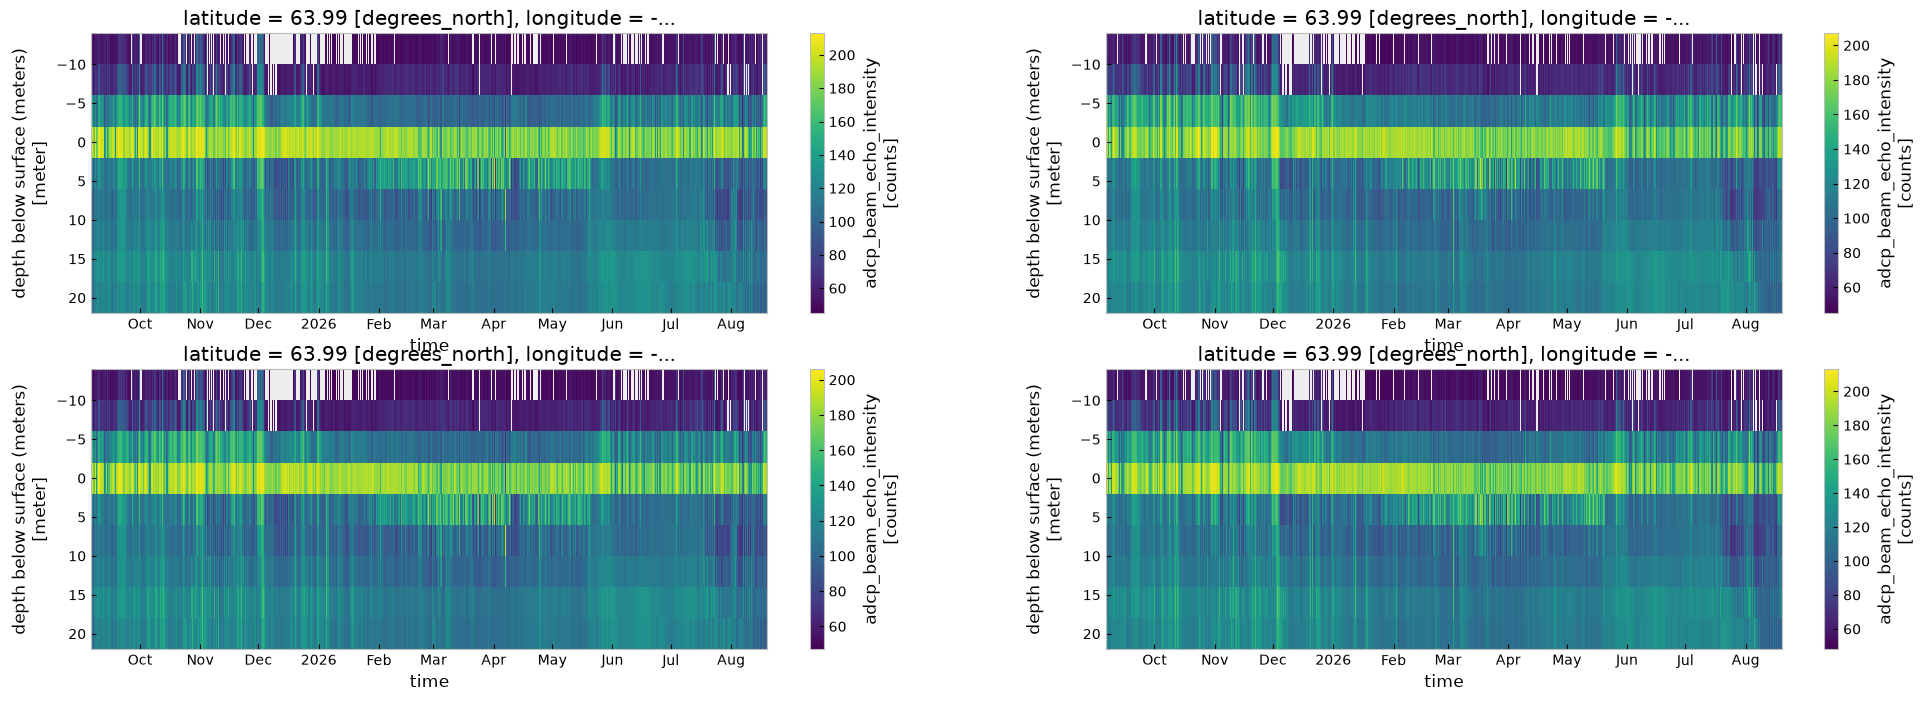

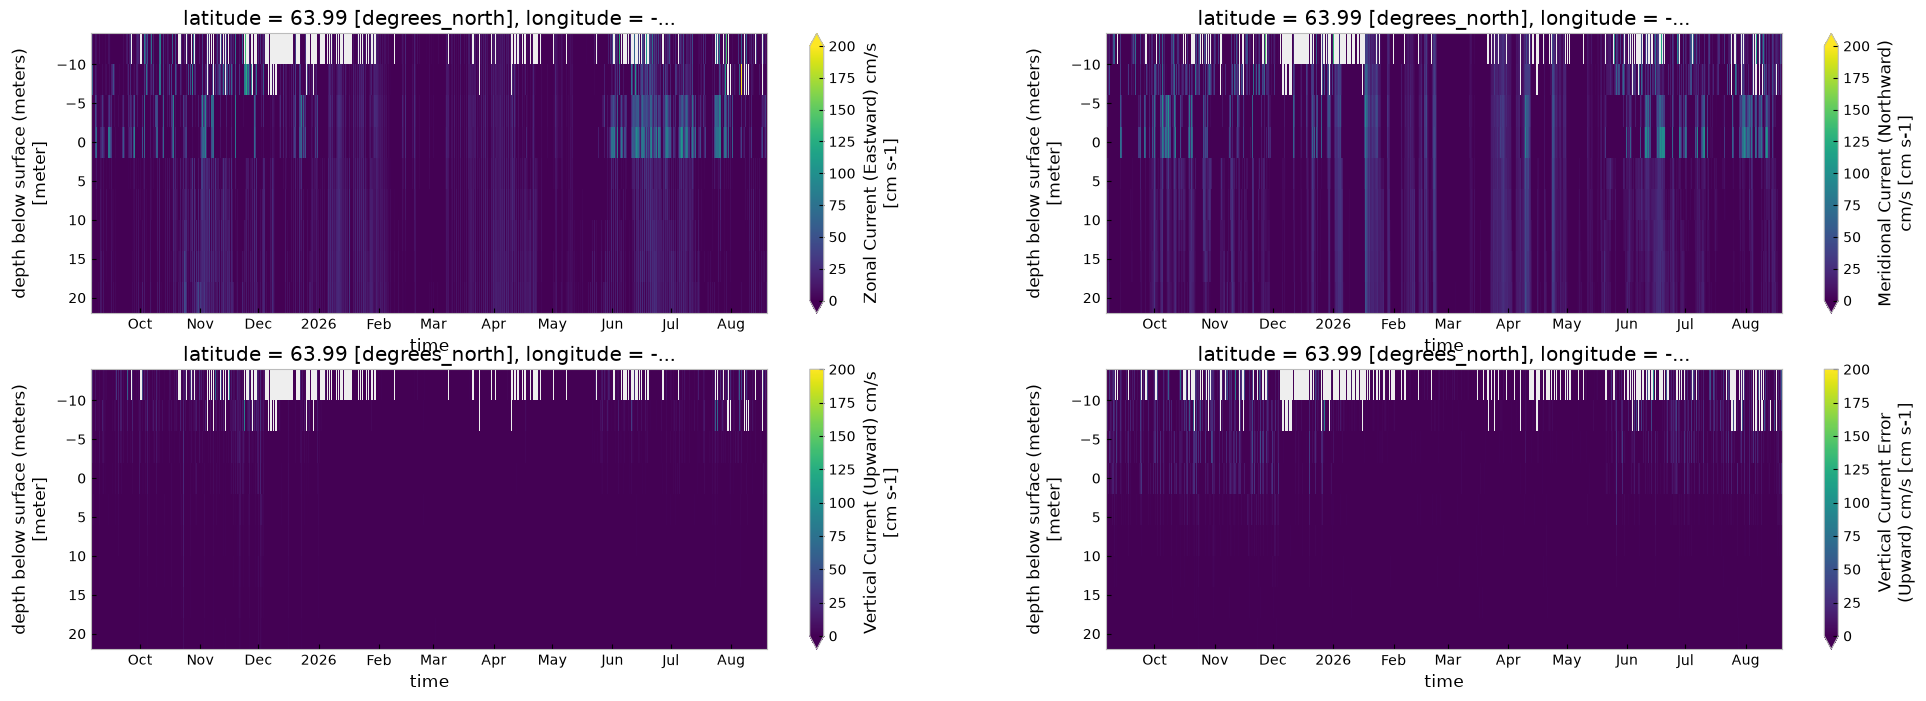

In [12]:
#optional plotting

fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(24,8))
try:
    xdf['agc1'].T.plot(ax=axes[0,0], yincrease=False)
    xdf['agc2'].T.plot(ax=axes[0,1], yincrease=False)
    xdf['agc3'].T.plot(ax=axes[1,0], yincrease=False)
    xdf['agc4'].T.plot(ax=axes[1,1], yincrease=False)
except:
    pass

fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(24,8))
try:
    xdf['u_curr_comp'].T.plot(ax=axes[0,0],vmin=0, vmax=200, yincrease=False)
    xdf['v_curr_comp'].T.plot(ax=axes[0,1],vmin=0, vmax=200, yincrease=False)
    xdf['w_curr_comp'].T.plot(ax=axes[1,0],vmin=0, vmax=200, yincrease=False)
    xdf['w_curr_comp_err'].T.plot(ax=axes[1,1],vmin=0, vmax=200, yincrease=False)
except:
    pass

In [13]:
try:
    xdf.attrs['history'] = xdf.attrs['history']+'  removed U,V >750cm/s'
except:
    xdf.attrs['history'] = '  removed U,V >750cm/s'    

## Trim above surface (negative values)

In [14]:
ixdf = xdf.where(xdf.depth >=-0.).dropna(how='all',dim='depth')

In [15]:
ixdf.attrs['history'] = ixdf.attrs['history']+'  trimmed above surface'

In [16]:
ixdf.to_netcdf('25bsp14a_0026m.trimmed.nc')

In [17]:
xdf = xa.load_dataset('25bsp14a_0026m.trimmed.nc')

In [18]:
ixdf = xdf.interpolate_na(dim='time',max_gap='2H')

## Interpolate over singleton missing gaps linearly

In [19]:
ixdf.attrs['history'] = ixdf.attrs['history']+'  linearly interpolated 1hour gaps'

In [20]:
ixdf = ixdf.interpolate_na(dim='depth',max_gap=3)

In [21]:
ixdf.attrs['history'] = ixdf.attrs['history']+'  linearly interpolated 2 vertical bin'

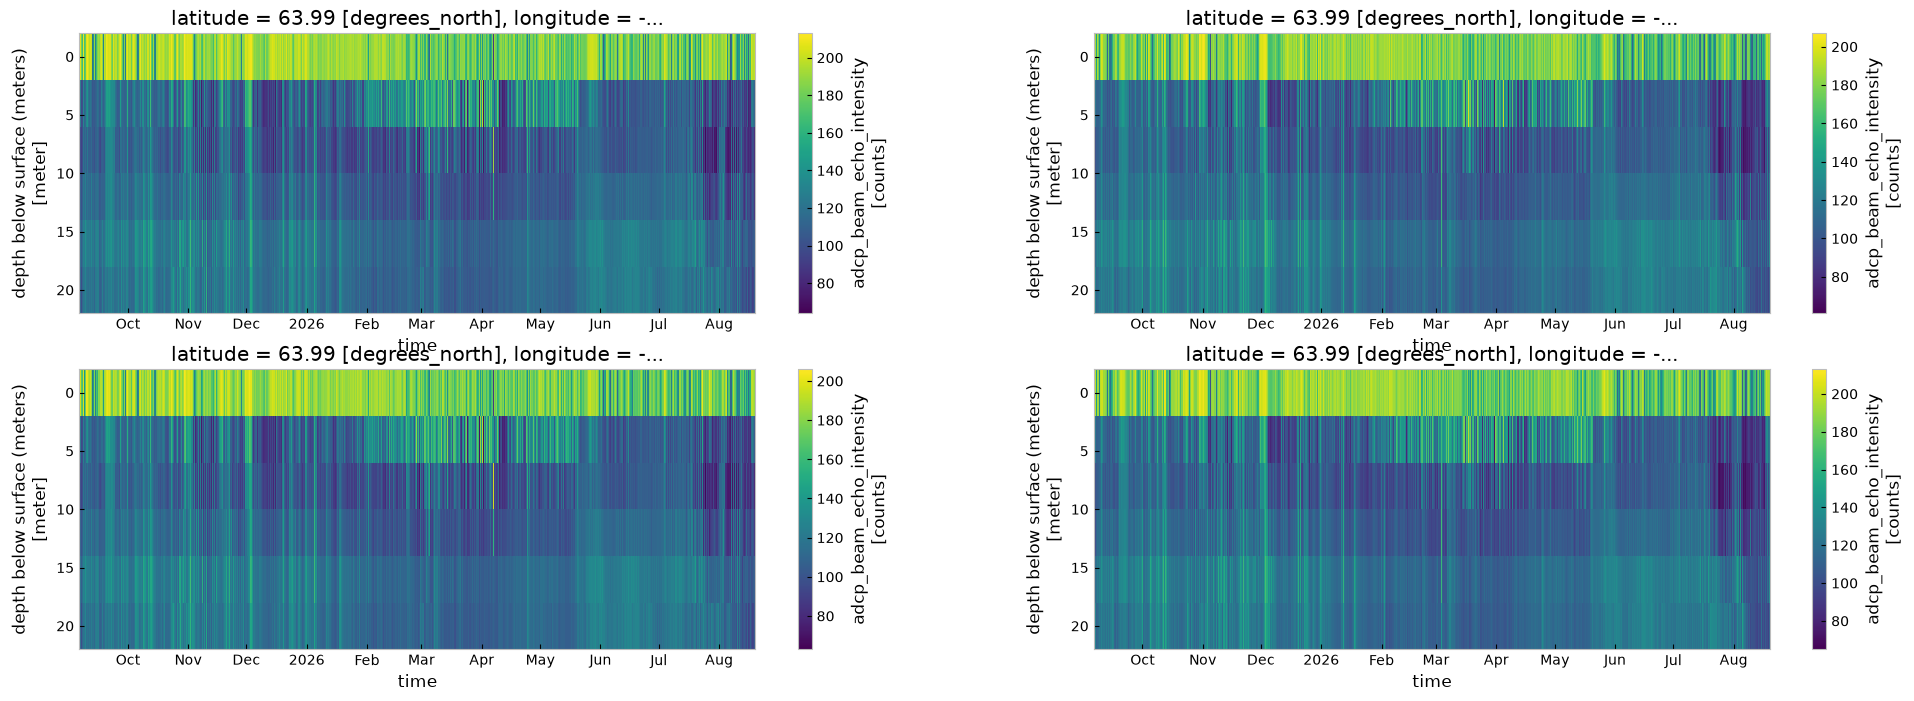

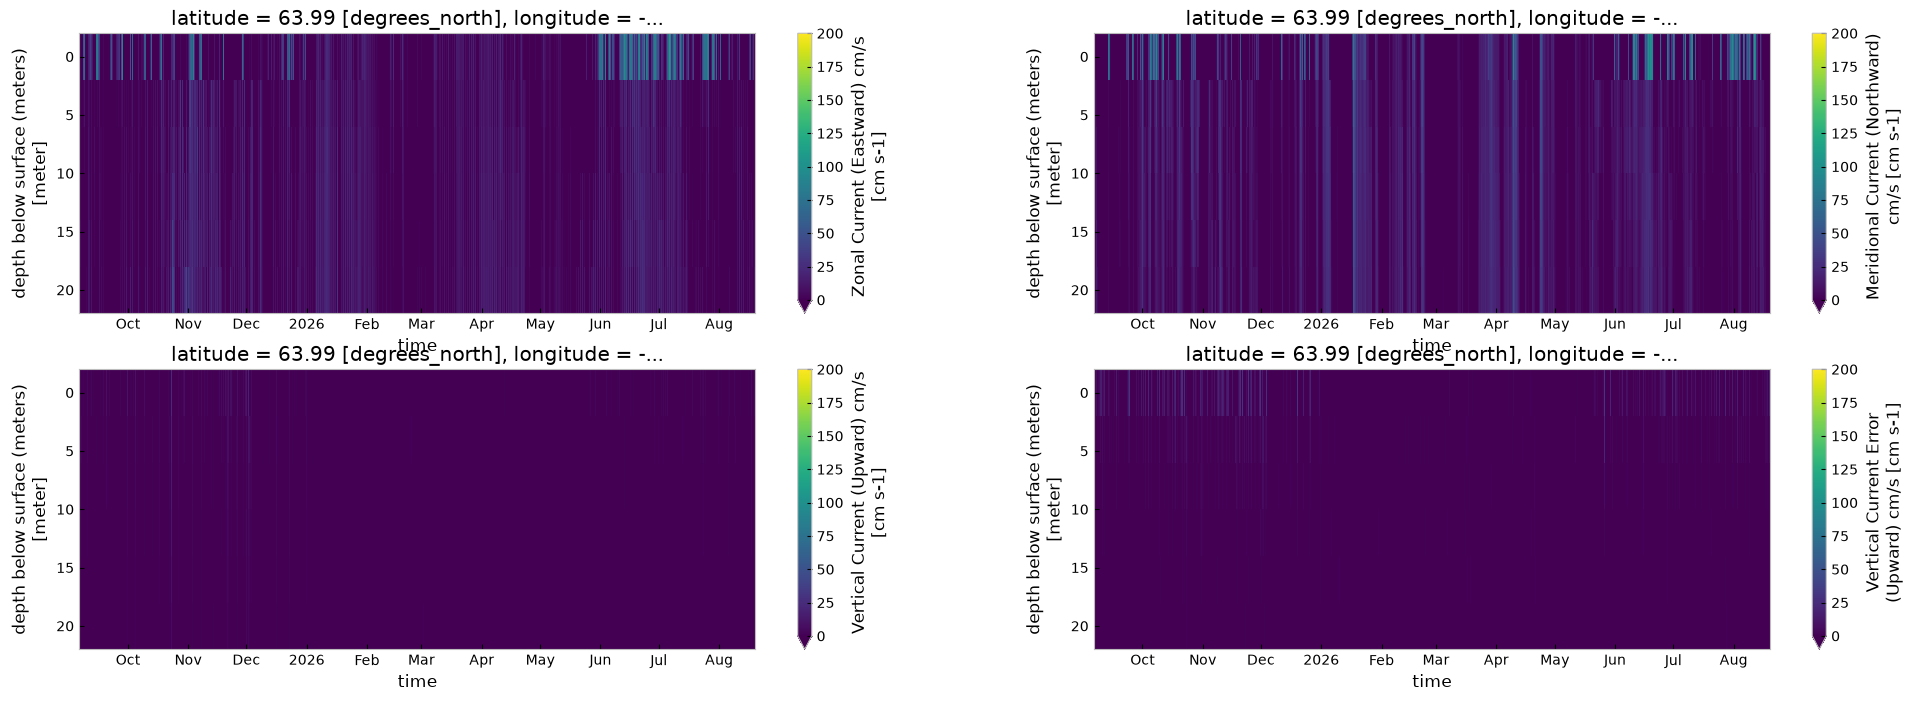

In [22]:

fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(24,8))
try:
    ixdf['agc1'].T.plot(ax=axes[0,0], yincrease=False)
    ixdf['agc2'].T.plot(ax=axes[0,1], yincrease=False)
    ixdf['agc3'].T.plot(ax=axes[1,0], yincrease=False)
    ixdf['agc4'].T.plot(ax=axes[1,1], yincrease=False)
except:
    pass

fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(24,8))
try:
    ixdf['u_curr_comp'].T.plot(ax=axes[0,0],vmin=0, vmax=200, yincrease=False)
    ixdf['v_curr_comp'].T.plot(ax=axes[0,1],vmin=0, vmax=200, yincrease=False)
    ixdf['w_curr_comp'].T.plot(ax=axes[1,0],vmin=0, vmax=200, yincrease=False)
    ixdf['w_curr_comp_err'].T.plot(ax=axes[1,1],vmin=0, vmax=200, yincrease=False)
except:
    pass

In [23]:
ixdf.to_netcdf('26bsp14a_wcp_velein.filtered.nc')